# LAB EVALUATION

In [23]:
import pandas as pd
import numpy as np 
from scipy import stats
import seaborn as sns
from sklearn.preprocessing import RobustScaler

In [24]:
df = pd.read_excel("lab6evaluation.xlsx")
df

,Student_ID,Age,Study_Hours,Attendance,Exam_Marks
0,S001,20,4.5,85,2
1,S002,21,5.0,90,78
2,S003,20,3.5,80,65
3,S004,150,18.0,95,82
4,S005,21,4.0,2,70


## Detect outliers using the IQR method

In [25]:
numeric_df= df.select_dtypes(include=[np.number])
df_1=numeric_df.copy()
df_2=numeric_df.copy()
df_3=numeric_df.copy()

Q1= numeric_df.quantile(0.25)
Q3= numeric_df.quantile(0.75)
IQR= Q3-Q1

outlier_iqr= ((numeric_df<(Q1-1.5*IQR)) | (numeric_df>(Q3+1.5*IQR)))
outlier_iqr

,Age,Study_Hours,Attendance,Exam_Marks
0,False,False,False,True
1,False,False,False,False
2,False,False,False,False
3,True,True,False,False
4,False,False,True,False


## Visualize detected outliers using box plots

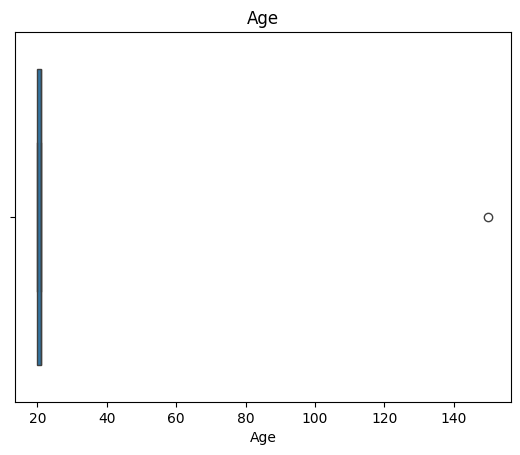

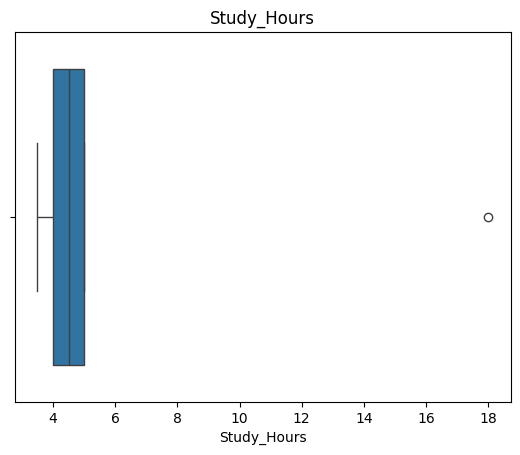

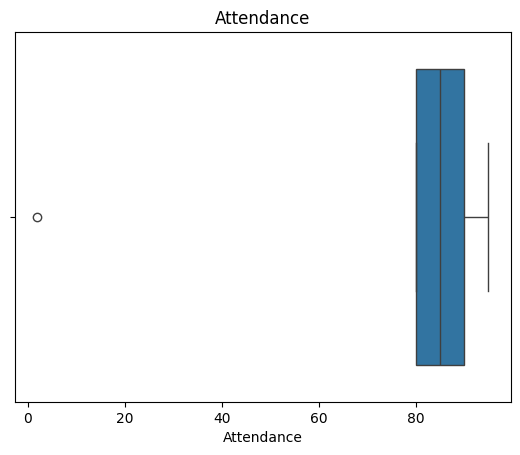

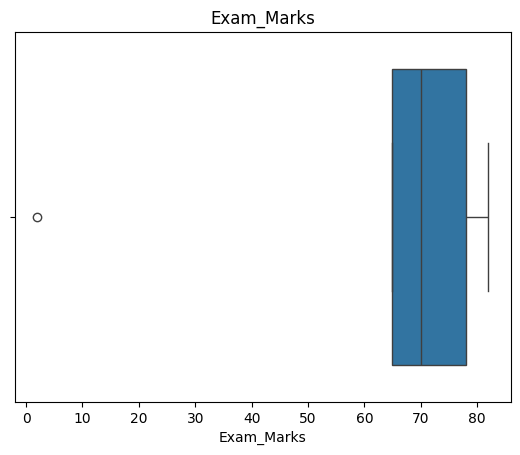

In [26]:
import matplotlib.pyplot as plt

for col in numeric_df.columns:
    sns.boxplot(x=numeric_df[col])
    plt.title(col)
    plt.show()

## Handle outliters using removal technique

In [27]:
df_1=df_1[~outlier_iqr.any(axis=1)]
df_1

,Age,Study_Hours,Attendance,Exam_Marks
1,21,5.0,90,78
2,20,3.5,80,65


## Handle outliers using median replacement

In [28]:
for col in df_2.columns:
    median=numeric_df[col].median()
    df_2[col]=np.where(outlier_iqr[col],median,numeric_df[col])

df_2

,Age,Study_Hours,Attendance,Exam_Marks
0,20.0,4.5,85.0,70.0
1,21.0,5.0,90.0,78.0
2,20.0,3.5,80.0,65.0
3,21.0,4.5,95.0,82.0
4,21.0,4.0,85.0,70.0


## Handle Outliers using capping/winsorization 

In [29]:
for col in df_3.columns:
    lower_limit=Q1[col]-1.5*IQR[col]
    upper_limit=Q3[col]+1.5*IQR[col]
    df_3[col]=np.where(df_3[col]<lower_limit,lower_limit,df_3[col])
    df_3[col]=np.where(df_3[col]>upper_limit,upper_limit,df_3[col])

df_3

,Age,Study_Hours,Attendance,Exam_Marks
0,20.0,4.5,85.0,45.5
1,21.0,5.0,90.0,78.0
2,20.0,3.5,80.0,65.0
3,22.5,6.5,95.0,82.0
4,21.0,4.0,65.0,70.0


## Compare the three handling techniques using statistical measures

In [30]:
comparison=pd.concat([
    numeric_df.agg(['count','mean','median','std']),
    df_1.agg(['count','mean','median','std']),
    df_2.agg(['count','mean','median','std']),
    df_3.agg(['count','mean','median','std'])
],keys=['Original','Removal','Median Replacement','Winsorization'])
comparison

Age  Study_Hours  Attendance  Exam_Marks
Original           count    5.000000     5.000000    5.000000    5.000000
                   mean    46.400000     7.000000   70.400000   59.400000
                   median  21.000000     4.500000   85.000000   70.000000
                   std     57.916319     6.174545   38.643240   32.768888
Removal            count    2.000000     2.000000    2.000000    2.000000
                   mean    20.500000     4.250000   85.000000   71.500000
                   median  20.500000     4.250000   85.000000   71.500000
                   std      0.707107     1.060660    7.071068    9.192388
Median Replacement count    5.000000     5.000000    5.000000    5.000000
                   mean    20.600000     4.300000   87.000000   73.000000
                   median  21.000000     4.500000   85.000000   70.000000
                   std      0.547723     0.570088    5.700877    6.855655
Winsorization      count    5.000000     5.000000    5.000000    5.000000
                   mean    20.900000     4.700000   83.000000   68.100000
                   median  21.000000     4.500000   85.000000   70.000000
                   std      1.024695     1.151086   11.510864   14.275854

## Select and justify the most suitable handling technique

In [31]:
print("Winsorization is the best method for handling outliers, cz it preserves the all data with good values.")

Winsorization is the best method for handling outliers, cz it preserves the all data with good values.
